**Registration Attribution**

The company acquires users through performance marketing.
Registrations are attributed to the channels from which the users originated.
Some registrations cannot be attributed due to browser privacy settings and anti-tracking tools.
The proportion of unattributed users varies depending on the traffic source.

day – day number

google / facebook / tiktok / snapchat – number of attributed registrations from the respective source

unattributed – number of unattributed registrations

**Question**: What percentage of registrations remains unattributed for each source?

**Approach**

To solve the problem with attribution of registrations, linear regression was chosen.

The main task of the model: to decompose the sum of unattributed actions into the contribution of each of the methods (in this task - into channels).

In general, linear regression has the following form: y = w1 * x1 + w2 * x2 + ... + wn * xn

In the context of the task, it would look like this: unattributed = w1 * google + w2 * facebook + w3 * tiktok + w4 * snapchat .

The found coefficients w will demonstrate the ratio of unattributed registrations to attributed ones for each channel.

In [1]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor


In [2]:
input_df = pd.read_csv("/content/task1(attribution).csv")

print(input_df)

     day  google  facebook  tiktok  snapchat  unattributed
0      1     186         0       0         0            27
1      2     207         0       0         0            30
2      3     220         0       0         0            34
3      4     172         0       0         0            24
4      5     214         0       0         0            33
..   ...     ...       ...     ...       ...           ...
148  149     328       101     108        87            73
149  150     275       123     134        98            87
150  151     358       111      96        56            94
151  152     397       195      87        80            85
152  153     264       180     108        80            73

[153 rows x 6 columns]


# EDA
Performing EDA in order to better understand its structure, detect potential problems and interesting trends.

In [3]:
missing_pct = input_df.isna().mean() * 100
print(f"Missing data in df:\n{missing_pct}")

# no missing data in the dataframe

Missing data in df:
day             0.0
google          0.0
facebook        0.0
tiktok          0.0
snapchat        0.0
unattributed    0.0
dtype: float64


In [4]:
print(input_df.describe())

              day      google    facebook      tiktok    snapchat  \
count  153.000000  153.000000  153.000000  153.000000  153.000000   
mean    77.000000  226.803922   37.732026   30.712418    5.281046   
std     44.311398   68.163412   61.570243   82.259512   18.631982   
min      1.000000    0.000000    0.000000    0.000000    0.000000   
25%     39.000000  179.000000    0.000000    0.000000    0.000000   
50%     77.000000  218.000000    0.000000    0.000000    0.000000   
75%    115.000000  275.000000   77.000000    0.000000    0.000000   
max    153.000000  397.000000  198.000000  370.000000   98.000000   

       unattributed  
count    153.000000  
mean      43.718954  
std       32.285620  
min        0.000000  
25%       27.000000  
50%       33.000000  
75%       45.000000  
max      171.000000  


In [5]:
input_df = input_df.drop_duplicates()
print(input_df)

# no data was removed from the dataframe while dropping duplicate rows. Each row is unique

     day  google  facebook  tiktok  snapchat  unattributed
0      1     186         0       0         0            27
1      2     207         0       0         0            30
2      3     220         0       0         0            34
3      4     172         0       0         0            24
4      5     214         0       0         0            33
..   ...     ...       ...     ...       ...           ...
148  149     328       101     108        87            73
149  150     275       123     134        98            87
150  151     358       111      96        56            94
151  152     397       195      87        80            85
152  153     264       180     108        80            73

[153 rows x 6 columns]


Overall, there are 153 days.

# Linear Regression Model

In [6]:
X = input_df[["google", "facebook", "tiktok", "snapchat"]]
y = input_df["unattributed"]


In [7]:
df_model = X.copy()
df_model["unattributed"] = y

# creating and fitting the linear regression model in R style
model = smf.ols("unattributed ~ google + facebook + tiktok + snapchat - 1", data=df_model).fit()

coefficients = model.params
p_values = model.pvalues
pct_unattributed = (coefficients / (1 + coefficients)) * 100

results_summary = pd.DataFrame(
    {
        "Coefficients (w)": coefficients,
        "% unattributed": pct_unattributed,
        "p-value": p_values,
        "Statistically Significant (p < 0.05)": p_values < 0.05
    }
).round(4)

print(model.summary())
print(f"\n{"-" * 100}\n")
print(results_summary)

                                 OLS Regression Results                                
Dep. Variable:           unattributed   R-squared (uncentered):                   0.993
Model:                            OLS   Adj. R-squared (uncentered):              0.993
Method:                 Least Squares   F-statistic:                              5686.
Date:                Sun, 15 Nov 2026   Prob (F-statistic):                   9.56e-162
Time:                        11:40:50   Log-Likelihood:                         -443.07
No. Observations:                 153   AIC:                                      894.1
Df Residuals:                     149   BIC:                                      906.3
Df Model:                           4                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

**Model Findings**

The regression model demonstrates excellent fit (R^2 ~ 0.993).
Google, Facebook and Tiktok show positive proved impact (with theirs p-value being < 0.05), while Snapchat is considered statistically insignificant (p-value ~ 0.86), demonstrating unreliable unattributed conversions.

Tiktok has the highest unattributed rate (~ 20%), while Google and Facebook have respectively ~ 12% and ~6%.


In [8]:
# checking for multicolearity
vif_data = pd.DataFrame()
vif_data["Channel"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif_data)

    Channel       VIF
0    google  1.632599
1  facebook  2.539109
2    tiktok  3.534156
3  snapchat  1.877175


The VIF values demonstate the absense of multicollinearity (VIF < 5).

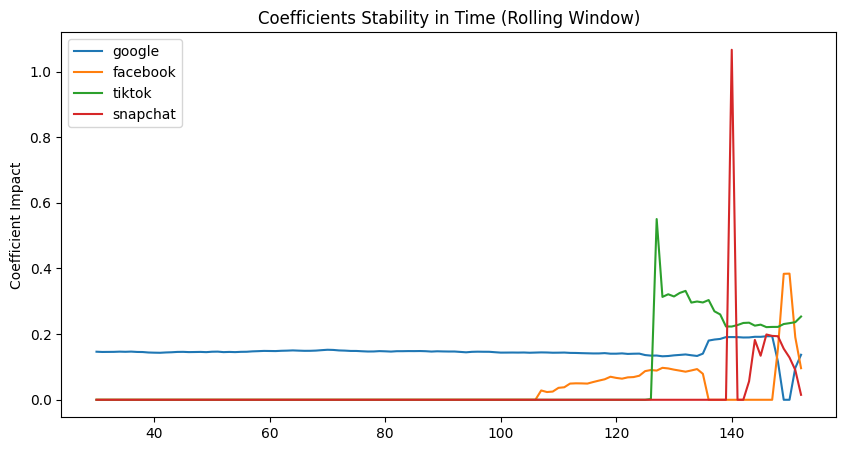

In [9]:
# coefficients stability in time
rolling_coefs = []
window = 30

for i in range(window, len(input_df)):
    X_window = X.iloc[i-window:i]
    y_window = y.iloc[i-window:i]

    m = LinearRegression(fit_intercept=False, positive=True).fit(X_window, y_window)
    rolling_coefs.append(m.coef_)

rolling_df = pd.DataFrame(rolling_coefs, columns=X.columns, index=input_df.index[window:])
rolling_df.plot(figsize=(10, 5), title="Coefficients Stability in Time (Rolling Window)")
plt.ylabel("Coefficient Impact")
plt.show()

The rolling window stability analysis reveals that Google is the only channel with stable coefficients over time.

Tiktok and Facebook were localized only in later period. While Snapchat has extreme instability near the end of the timeline, confirming the hypothesis about its lack of statistical reliability in the regression model.

# Summary

**Core findings**

The regression model successfully maps unattributed registrations across channels with high accuracy (R^2 ~ 0.993). The proporsion of unattributed actions varies the following way:
- Tiktok (20.7% unattributed): Shows the highest value.
- Google (12.7% unattributed): Maintains the predictable attribution gap.
- Facebook (6.4% unattributed): Demonstates the most reliable tracking among channels, with only few lost conversions.
- Snapchat (Statistically Insignificant): Shows no reliable mathematical relationship with unattributed registrations (p = 0.866).

**Model Reliability**

Google, Facebook and Tiktok have strong statistical evidence (p < 0.05), meaning their impact is real and not random. At the same time, Snapchat is statistically insignificant and should be excluded from strategic attribution decisions.

**Time Stability**

Google exhibits long-term stability, maintaing the same coefficients over time. Tiktok and Facebook show minor shifts in later periods, likely reacting to users' behavior or change of campaign.
Snapchat exhibits extreme spikes close to the end of the timeline, aligning with its lack of statistical significance.

**Bussiness Recommendations**

- Investigate why the Tiktok has the highest unattributed rate among channels. Implementing server-side tracking is recommended.
- Relying on the Snapchat current model is not recommended, as it shows high instability.